# makemore Part 3 — Revision Notebook
### Activations, Gradients & BatchNorm  ·  Karpathy's *Neural Networks: Zero to Hero*, lecture 4

**Lecture:** [Building makemore Part 3: Activations & Gradients, BatchNorm](https://www.youtube.com/watch?v=P6sfmUTpUmc)

**How every section works** (intuition first, then proof):

 meaning |
|---|
| **ELI5** – a plain-language picture, no maths |
| **See it** – a plot that makes the idea visible |
| **Verify it** – numbers/code that confirm the intuition |
| **Watch** – a 3Blue1Brown (or Karpathy) video for that exact idea |

**Map of the lecture**

| § | Topic | Lecture time |
|---|---|---|
| 0 | Recap & setup | start |
| 1 | Fix the *initial loss* (confidently-wrong network) | first part |
| 2 | *tanh saturation* & dead neurons | first part |
| 3 | *Variance preservation* → Kaiming init | [0:27:53](https://www.youtube.com/watch?v=P6sfmUTpUmc&t=1673s) |
| 4 | *BatchNorm* (+ coupling, running stats, bias is useless) | [0:40:40](https://www.youtube.com/watch?v=P6sfmUTpUmc&t=2440s) |
| 5 | Train the real model with BatchNorm | after §4 |
| 6 | *PyTorch-ify*: `Linear`, `BatchNorm1d`, `Tanh` | [1:18:35](https://www.youtube.com/watch?v=P6sfmUTpUmc&t=4715s) |
| 7 | *Diagnostics*: activations, gradients, update:data ratio | [1:26:51](https://www.youtube.com/watch?v=P6sfmUTpUmc&t=5211s) |
| 8 | Self-test, exercises, cheat-sheet | – |

> Runtime: ~3–6 min on a laptop CPU (§5 trains 200k steps; lower `max_steps` there if you're in a hurry).
> Data: `names.txt` is downloaded automatically if it isn't next to the notebook.

##  The one idea behind the whole lecture

Imagine a **long chain of people whispering a message** (that's a deep network's *forward pass*), and then the *last* person shouting corrections back down the chain (that's the *backward pass*).

Three things can go wrong:

1. **Too loud** → the message gets bigger and bigger until it's noise (*exploding*).
2. **Too quiet** → the message fades to nothing (*vanishing*).
3. **Stuck** → some people have their hands on their ears and never react to anyone (*saturated / dead neurons*).

**Everything in this lecture is a trick to keep the "volume" of signals healthy** — going forward (activations) *and* going backward (gradients):

| Trick | What it does in the whisper-chain |
|---|---|
| Small `W2`, zero `b2` | the last person doesn't shout a confident wrong answer at step 0 |
| Scale `W1` by `gain/√fan_in` (Kaiming) | each person passes on the message at the *same volume* they received it |
| BatchNorm | a moderator re-sets the volume to "normal" after every person |
| Diagnostic plots | a volume meter on every person in the chain |

🎬 **Warm-up (optional but recommended before you start): what *is* the network we're training?**
[Open on YouTube](https://www.youtube.com/watch?v=aircAruvnKk)

## 0 · Setup & recap of Part 2

We're still building a **character-level name generator**: look at the previous 3 characters, predict the next one.

```
 3 chars ─► Embedding C (27×10) ─► concat (30) ─► Linear W1 (30×200) ─► [BatchNorm] ─► tanh ─► Linear W2 (200×27) ─► logits ─► softmax ─► loss
   "emm"          each char → 10 numbers         "hidden pre-activation"                     "hidden activation"                 27 scores
```

In [2]:
import math, random, os, time, urllib.request
import numpy as np
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
%matplotlib inline

plt.rcParams.update({
    'figure.dpi': 100, 'axes.grid': True, 'grid.alpha': 0.25,
    'axes.spines.top': False, 'axes.spines.right': False, 'font.size': 10,
})

# data: ~32k first names
if not os.path.exists('names.txt'):
    urllib.request.urlretrieve('https://raw.githubusercontent.com/karpathy/makemore/master/names.txt', 'names.txt')
words = open('names.txt', 'r').read().splitlines()
print(len(words), words[:8])

# vocabulary: '.' = start/end token (index 0), a..z = 1..26
chars = sorted(list(set(''.join(words))))
stoi = {s: i + 1 for i, s in enumerate(chars)}
stoi['.'] = 0
itos = {i: s for s, i in stoi.items()}
vocab_size = len(itos)
print('vocab_size =', vocab_size)

# dataset: X = 3 previous chars, Y = next char
block_size = 3
def build_dataset(words):
    X, Y = [], []
    for w in words:
        context = [0] * block_size
        for ch in w + '.':
            ix = stoi[ch]
            X.append(context); Y.append(ix)
            context = context[1:] + [ix]      # slide the window
    return torch.tensor(X), torch.tensor(Y)

random.seed(42); random.shuffle(words)
n1, n2 = int(0.8 * len(words)), int(0.9 * len(words))
Xtr,  Ytr  = build_dataset(words[:n1])        # 80% train
Xdev, Ydev = build_dataset(words[n1:n2])      # 10% dev
Xte,  Yte  = build_dataset(words[n2:])        # 10% test
print(Xtr.shape, Xdev.shape, Xte.shape)

n_embd, n_hidden = 10, 200

32033 ['emma', 'olivia', 'ava', 'isabella', 'sophia', 'charlotte', 'mia', 'amelia']
vocab_size = 27
torch.Size([182625, 3]) torch.Size([22655, 3]) torch.Size([22866, 3])


---
## 1 · Fix the initial loss  (the "hockey stick")

###  ELI5
Someone asks you to guess a letter out of 27, and you've seen **zero** data. The *honest* answer is "no idea — each letter is equally likely (1/27)".

The loss (cross-entropy) is "how surprised were you by the right answer": $-\ln p(\text{correct})$.
Honest guess → $-\ln(1/27) = 3.296$.

But a randomly initialised network often says *"I'm 99% sure it's **q**!"*. When the truth turns out to be **e**, it's confidently wrong, and the loss is huge (10, 20, 27…).
The first few hundred training steps are then wasted just **un-learning that overconfidence** → the loss curve looks like a **hockey stick**.

🎬 **Watch:** what a "loss" is and why we minimise it — 3Blue1Brown, *Gradient descent, how neural networks learn*
[YouTube](https://www.youtube.com/watch?v=IHZwWFHWa-w)

### 🔬 Expected loss at init

In [3]:
print(f'-ln(1/27) = {-math.log(1/27):.4f}   <- the loss we SHOULD see at step 0')

-ln(1/27) = 3.2958   <- the loss we SHOULD see at step 0


###  What *confident-and-wrong* looks like (red bar = the true next letter)

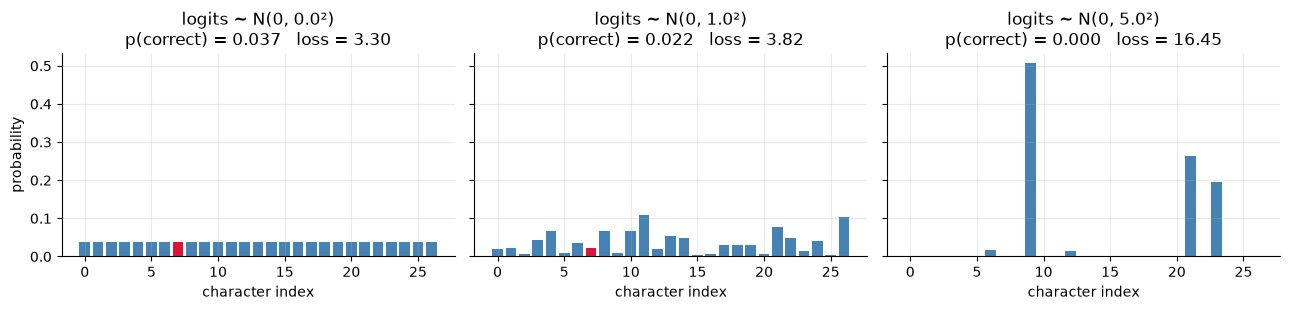

In [4]:
torch.manual_seed(1)
true_ix = 7
fig, axes = plt.subplots(1, 3, figsize=(13, 3.2), sharey=True)
for ax, s in zip(axes, [0.0, 1.0, 5.0]):
    logits = torch.randn(vocab_size) * s           # s = how "loud" the logits are
    p = F.softmax(logits, 0)
    ax.bar(range(vocab_size), p, color=['crimson' if i == true_ix else 'steelblue' for i in range(vocab_size)])
    ax.set_title(f'logits ~ N(0, {s}²)\np(correct) = {p[true_ix]:.3f}   loss = {-p[true_ix].log():.2f}')
    ax.set_xlabel('character index')
axes[0].set_ylabel('probability')
plt.tight_layout(); plt.show()

###  Loss vs. logit loudness
Average loss over many random guesses, as we turn up the volume of the logits.
The loss is *minimal* (≈3.30) when logits are ~0, and explodes as they get loud.

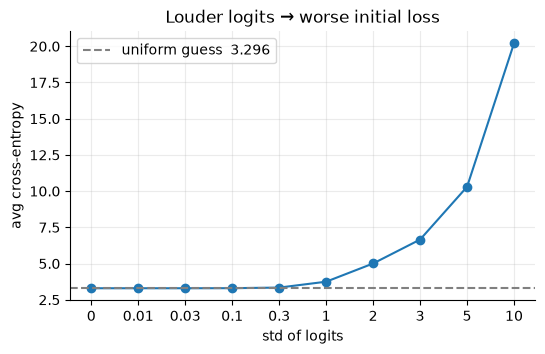

logit std     0: loss 3.296
logit std  0.01: loss 3.296
logit std  0.03: loss 3.296
logit std   0.1: loss 3.300
logit std   0.3: loss 3.342
logit std     1: loss 3.748
logit std     2: loss 5.005
logit std     3: loss 6.657
logit std     5: loss 10.299
logit std    10: loss 20.209


In [5]:
torch.manual_seed(0)
scales = [0, 0.01, 0.03, 0.1, 0.3, 1, 2, 3, 5, 10]
Y = torch.randint(0, vocab_size, (20000,))
losses = [F.cross_entropy(torch.randn(20000, vocab_size) * s, Y).item() for s in scales]

plt.figure(figsize=(6, 3.5))
plt.plot(range(len(scales)), losses, 'o-')
plt.axhline(-math.log(1/27), color='gray', ls='--', label='uniform guess  3.296')
plt.xticks(range(len(scales)), scales); plt.xlabel('std of logits'); plt.ylabel('avg cross-entropy')
plt.legend(); plt.title('Louder logits → worse initial loss'); plt.show()
for s, l in zip(scales, losses): print(f'logit std {s:>5}: loss {l:.3f}')

### The fix
* `b2 = 0` → no output bias pushing towards any letter.
* `W2 *= 0.01` → logits ≈ 0 → softmax ≈ uniform.
* **Don't set `W2` exactly to 0**: a tiny random value is kept for *symmetry breaking* (otherwise every output neuron gets identical gradients). With one layer after it, exactly zero is survivable, but it's a bad habit for deeper nets.

###  Train both and compare (3000 steps each)

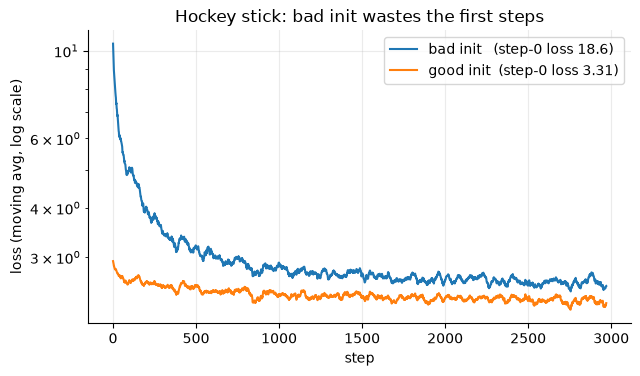

avg loss over steps 0-299   bad: 5.23  good: 2.64
avg loss over steps 2700+   bad: 2.58  good: 2.32


In [6]:
def train_simple(w2_scale, b2_scale, steps=3000, lr=0.1, batch_size=32, seed=2147483647):
    g = torch.Generator().manual_seed(seed)
    C  = torch.randn((vocab_size, n_embd), generator=g)
    W1 = torch.randn((n_embd * block_size, n_hidden), generator=g) * 0.2
    b1 = torch.randn(n_hidden, generator=g) * 0.01
    W2 = torch.randn((n_hidden, vocab_size), generator=g) * w2_scale
    b2 = torch.randn(vocab_size, generator=g) * b2_scale
    params = [C, W1, b1, W2, b2]
    for p in params: p.requires_grad = True
    out = []
    for i in range(steps):
        ix = torch.randint(0, Xtr.shape[0], (batch_size,), generator=g)
        emb = C[Xtr[ix]].view(batch_size, -1)
        h = torch.tanh(emb @ W1 + b1)
        loss = F.cross_entropy(h @ W2 + b2, Ytr[ix])
        for p in params: p.grad = None
        loss.backward()
        for p in params: p.data += -lr * p.grad
        out.append(loss.item())
    return out

bad  = train_simple(w2_scale=1.0,  b2_scale=1.0)   # "default" randn init
good = train_simple(w2_scale=0.01, b2_scale=0.0)   # fixed init

def smooth(x, k=30): return np.convolve(x, np.ones(k) / k, mode='valid')
plt.figure(figsize=(7, 3.8))
plt.plot(smooth(bad),  label=f'bad init   (step-0 loss {bad[0]:.1f})')
plt.plot(smooth(good), label=f'good init  (step-0 loss {good[0]:.2f})')
plt.yscale('log'); plt.xlabel('step'); plt.ylabel('loss (moving avg, log scale)')
plt.title('Hockey stick: bad init wastes the first steps'); plt.legend(); plt.show()
print('avg loss over steps 0-299   bad: %.2f  good: %.2f' % (np.mean(bad[:300]), np.mean(good[:300])))
print('avg loss over steps 2700+   bad: %.2f  good: %.2f' % (np.mean(bad[-300:]), np.mean(good[-300:])))

**Takeaway.** Always check `loss at step 0 ≈ −ln(1/vocab_size)`. If it's much higher, your last layer is too loud. This is a 10-second sanity check that catches real bugs.

---
## 2 · tanh saturation & dead neurons

###  ELI5
`tanh` is a **light dimmer with a stop at each end**: turn the knob a little → brightness changes. Turn the knob **all the way** → the lamp is at max (+1) or min (−1) and wiggling the knob changes *nothing*.

During training, a neuron learns by asking *"if I wiggle my input, does the final loss change?"* That answer (the **gradient**) is multiplied by the lamp's sensitivity, $1 - \tanh^2(x)$.

* knob in the middle → sensitivity ≈ 1 → learns
* knob jammed at an end → sensitivity ≈ 0 → **gradient is killed, neuron learns nothing**

If a neuron is jammed at an end for *every* example, it's a **dead neuron** — it never recovers, because it never gets a gradient to fix itself.

🎬 **Watch:** *why* a zero local gradient stops everything upstream is the **chain rule** — 3Blue1Brown, *Backpropagation, intuitively* and *Backpropagation calculus*
[Ch.3](https://www.youtube.com/watch?v=Ilg3gGewQ5U) · [Ch.4](https://www.youtube.com/watch?v=tIeHLnjs5U8)

### 👀 The dimmer and its sensitivity
Backprop through tanh: $\;\dfrac{\partial L}{\partial x} = (1 - t^2)\cdot\dfrac{\partial L}{\partial t}\;$ where $t=\tanh(x)$.

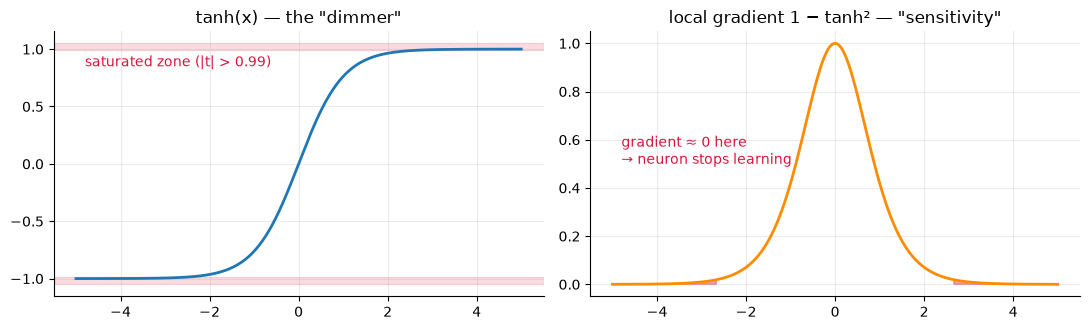

In [7]:
x = torch.linspace(-5, 5, 400)
t = torch.tanh(x)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
ax[0].plot(x, t, lw=2); ax[0].set_title('tanh(x) — the "dimmer"')
ax[0].axhspan(0.99, 1.05, color='crimson', alpha=.15); ax[0].axhspan(-1.05, -0.99, color='crimson', alpha=.15)
ax[0].text(-4.8, 0.85, 'saturated zone (|t| > 0.99)', color='crimson')
ax[1].plot(x, 1 - t**2, lw=2, color='darkorange'); ax[1].set_title('local gradient 1 − tanh² — "sensitivity"')
ax[1].fill_between(x, 0, 1 - t**2, where=(t.abs() > 0.99), color='crimson', alpha=.4)
ax[1].text(-4.8, 0.5, 'gradient ≈ 0 here\n→ neuron stops learning', color='crimson')
plt.tight_layout(); plt.show()

###  Does a too-big `W1` really saturate tanh?
We take a real batch of 32 examples, push it through `W1` with different scales, and look at the resulting `tanh` outputs.
**White pixel in the right-hand image = saturated** (|h| > 0.99). A fully white *column* is a dead neuron (for this batch).

W1 scale 1.0: mean local gradient (1-h²) = 0.134   |   saturated = 64.7%   |   dead neurons = 0
W1 scale 0.2: mean local gradient (1-h²) = 0.552   |   saturated = 3.2%   |   dead neurons = 0


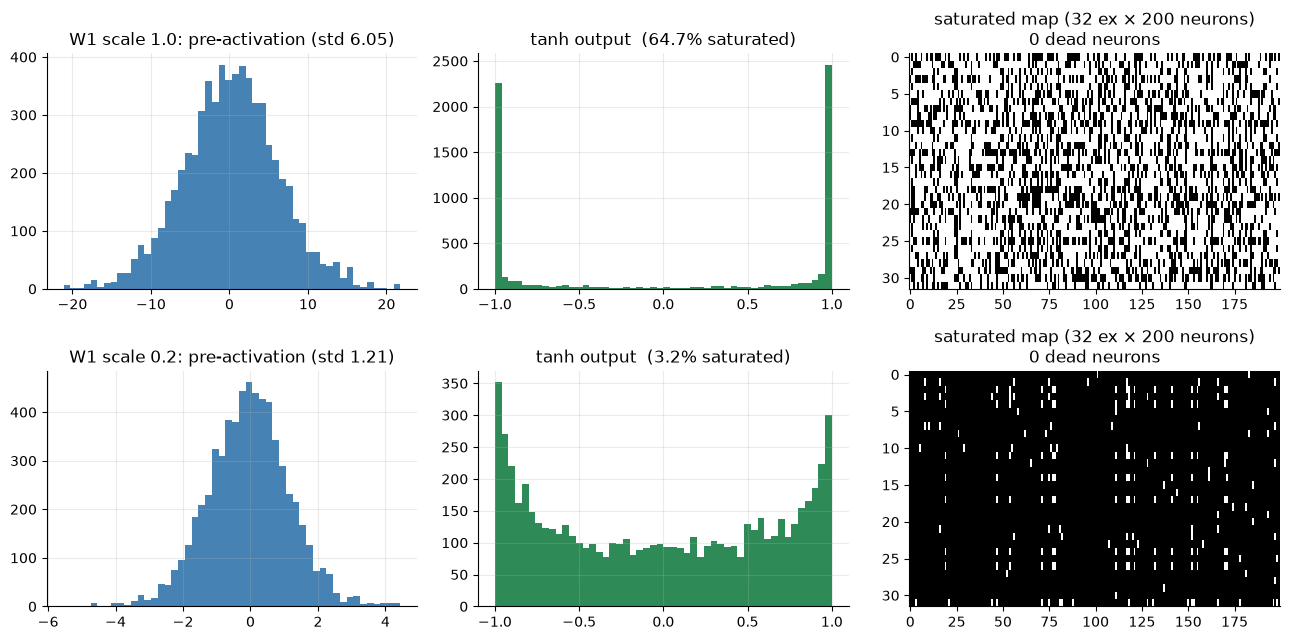

In [8]:
torch.manual_seed(42)
Cemb = torch.randn((vocab_size, n_embd))
ix = torch.randint(0, Xtr.shape[0], (32,))
embcat_fixed = Cemb[Xtr[ix]].view(32, -1)             # (32, 30): a fixed real batch used in §2 and §4

fig, axes = plt.subplots(2, 3, figsize=(13, 6.5))
for row, s in enumerate([1.0, 0.2]):
    W1_ = torch.randn((n_embd * block_size, n_hidden)) * s
    hpre = embcat_fixed @ W1_
    h = torch.tanh(hpre)
    sat = (h.abs() > 0.99).float()
    dead = (sat.mean(0) == 1.0).sum().item()
    axes[row, 0].hist(hpre.flatten(), bins=50, color='steelblue'); axes[row, 0].set_title(f'W1 scale {s}: pre-activation (std {hpre.std():.2f})')
    axes[row, 1].hist(h.flatten(), bins=50, color='seagreen');     axes[row, 1].set_title(f'tanh output  ({sat.mean()*100:.1f}% saturated)')
    axes[row, 2].imshow(sat, cmap='gray', interpolation='nearest', aspect='auto'); axes[row, 2].grid(False)
    axes[row, 2].set_title(f'saturated map (32 ex × 200 neurons)\n{dead} dead neurons')
    print(f'W1 scale {s}: mean local gradient (1-h²) = {(1 - h**2).mean():.3f}   |   saturated = {sat.mean()*100:.1f}%   |   dead neurons = {dead}')
plt.tight_layout(); plt.show()

**Reading the result.**
* Big `W1` (scale 1): pre-activation std ≈ 6 (≈ √30 — why? → §3), so ~65 % of the `tanh` outputs are jammed at ±1 and the mean local gradient (1 − h²) is only ≈ 0.13 → roughly 87 % of the gradient signal is thrown away at this layer.
* Smaller `W1` (scale 0.2): pre-activation std ≈ 1.2, only ≈ 3 % saturated, mean local gradient ≈ 0.55.
* No column is *fully* white in this batch of 32, so no neuron is strictly dead here — but the more saturated the layer, the more likely an entire column goes white (= dead for that batch, and permanently dead if it stays that way for all data).

**Same disease, other activations:** sigmoid saturates the same way; **ReLU** has "dead neurons" when the pre-activation is negative for *every* input (gradient exactly 0 there); leaky-ReLU / ELU avoid the flat zone.
**Dead at init vs. dead after training:** a too-high learning rate can knock healthy neurons into the flat zone permanently — same symptom, later in training.

---
## 3 · Variance preservation → Kaiming initialisation

###  ELI5 — the photocopier chain
Each layer is a **photocopier with a zoom knob**. You feed in a page; it comes out slightly zoomed.
* zoom 1.2× → after 30 copiers the page is 237× bigger → a black blob (*explode*)
* zoom 0.8× → after 30 copiers it's 0.001× → a blank page (*vanish*)
* zoom **exactly 1.0×** → the page arrives readable.

A `Linear` layer computes $y=\sum_{i=1}^{n} x_i w_i$ — **a sum of `n` random products**. Adding `n` independent random wiggles doesn't give you `n×` the wiggle; it gives you **√n ×** the wiggle (random ups and downs partly cancel). So with `fan_in = n` inputs and unit-variance weights, the output std is **≈ √n**. The cure is obvious: **divide the weights by √n**.

🎬 **Watch:** why sums of random things have a spread that grows like √n — 3Blue1Brown, *But what is the Central Limit Theorem?* (the "spread of a sum" part is the key idea)
[YouTube](https://www.youtube.com/watch?v=zeJD6dqJ5lo)

###  Verify: output std grows like √fan_in

In [9]:
torch.manual_seed(0)
print(f"{'fan_in':>7} | {'std(y), w~N(0,1)':>17} | {'sqrt(fan_in)':>12} | {'std(y), w~N(0,1/fan_in)':>24}")
for n in [10, 30, 100, 300, 1000]:
    x = torch.randn(2000, n)                         # unit-variance inputs
    w = torch.randn(n, 200)                          # unit-variance weights
    print(f'{n:>7} | {(x @ w).std():>17.2f} | {n**0.5:>12.2f} | {(x @ (w / n**0.5)).std():>24.3f}')

 fan_in |  std(y), w~N(0,1) | sqrt(fan_in) |  std(y), w~N(0,1/fan_in)
     10 |              3.09 |         3.16 |                    0.978
     30 |              5.47 |         5.48 |                    0.999
    100 |             10.06 |        10.00 |                    1.006
    300 |             17.30 |        17.32 |                    0.999
   1000 |             31.45 |        31.62 |                    0.994


###  The lecture's picture: x is unit Gaussian, `y = x@w` is much wider, dividing by √fan_in fixes it

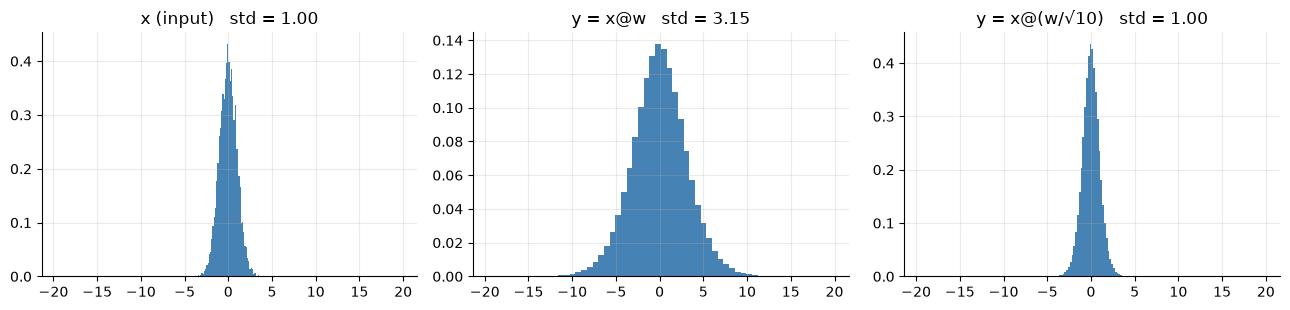

In [10]:
torch.manual_seed(0)
x = torch.randn(1000, 10); w = torch.randn(10, 200)
y_bad, y_good = x @ w, x @ (w / 10**0.5)
fig, ax = plt.subplots(1, 3, figsize=(13, 3.2), sharex=True)
for a, t, name in zip(ax, [x, y_bad, y_good], ['x (input)', 'y = x@w', 'y = x@(w/√10)']):
    a.hist(t.flatten(), bins=60, density=True, color='steelblue'); a.set_title(f'{name}   std = {t.std():.2f}')
plt.tight_layout(); plt.show()

###  Stack them: 40 linear layers, 3 different zoom knobs
Track the std of the activations layer by layer. (No non-linearity yet — pure photocopier chain.)

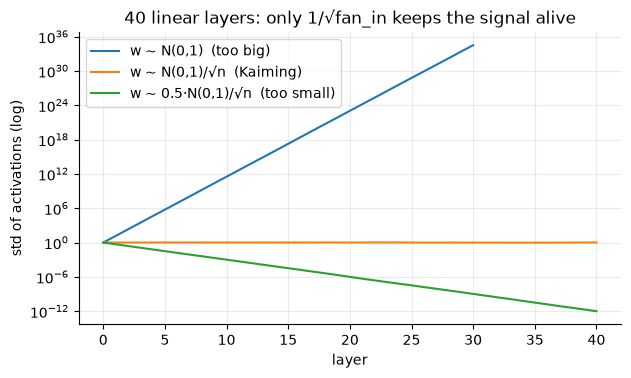

In [11]:
torch.manual_seed(0)
width, depth = 200, 40
def std_per_layer(scale_fn, act=lambda z: z, gain=1.0):
    h = torch.randn(1000, width); stds, sats = [h.std().item()], [0.0]
    for _ in range(depth):
        W = torch.randn(width, width) * scale_fn(width) * gain
        h = act(h @ W)
        stds.append(h.std().item()); sats.append((h.abs() > 0.97).float().mean().item())
    return stds, sats

plt.figure(figsize=(7, 3.8))
for label, fn in [('w ~ N(0,1)  (too big)', lambda n: 1.0),
                  ('w ~ N(0,1)/√n  (Kaiming)', lambda n: n**-0.5),
                  ('w ~ 0.5·N(0,1)/√n  (too small)', lambda n: 0.5 * n**-0.5)]:
    plt.plot(std_per_layer(fn)[0], label=label)
plt.yscale('log'); plt.xlabel('layer'); plt.ylabel('std of activations (log)')
plt.title('40 linear layers: only 1/√fan_in keeps the signal alive'); plt.legend(); plt.show()

###  But we have `tanh`, which *squashes*
`tanh` always shrinks the spread a bit (it caps values at ±1). So a pure `1/√n` makes the signal slowly fade. We need a **gain** — a little extra zoom — to compensate:

$$ w \sim \mathcal N\!\left(0,\ \Big(\tfrac{\text{gain}}{\sqrt{\text{fan\_in}}}\Big)^2\right) $$

| non-linearity | recommended gain |
|---|---|
| linear / identity, conv, sigmoid | 1 |
| **tanh** | **5/3 ≈ 1.667** |
| ReLU | √2 ≈ 1.414 (ReLU zeros half the signal, so double the variance) |
| leaky ReLU (slope *a*) | √(2/(1+a²)) |
| SELU | 3/4 |

###  Verify: tanh 40-layer stack with gain 1 / 5/3 / 3

gain 1.00: final-layer std = 0.101,  final-layer saturation = 0.0%
gain 1.67: final-layer std = 0.651,  final-layer saturation = 5.4%
gain 3.00: final-layer std = 0.835,  final-layer saturation = 40.0%


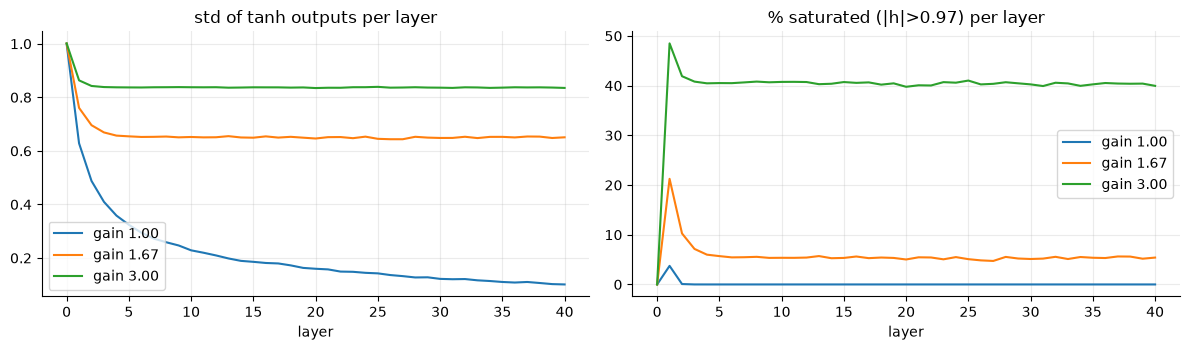

In [12]:
torch.manual_seed(0)
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
for g_ in [1.0, 5/3, 3.0]:
    stds, sats = std_per_layer(lambda n: n**-0.5, act=torch.tanh, gain=g_)
    ax[0].plot(stds, label=f'gain {g_:.2f}'); ax[1].plot(np.array(sats) * 100, label=f'gain {g_:.2f}')
    print(f'gain {g_:.2f}: final-layer std = {stds[-1]:.3f},  final-layer saturation = {sats[-1]*100:.1f}%')
ax[0].set_title('std of tanh outputs per layer'); ax[0].set_xlabel('layer'); ax[0].legend()
ax[1].set_title('% saturated (|h|>0.97) per layer'); ax[1].set_xlabel('layer'); ax[1].legend()
plt.tight_layout(); plt.show()

**Reading it.**
* gain 1 → std shrinks toward 0 (the signal fades; tanh lives in its linear zone and the net behaves like a *linear* net).
* gain 3 → neurons slam into ±1 (≈ 40 % saturated at *every* layer → most of the gradient is blocked).
* gain 5/3 → stable. (Note: the stable std is ≈ 0.65, **not 1** — tanh can never output std 1. What matters is that it *doesn't drift* across layers.)

###  Where does ≈ 5/3 come from?
For unit-Gaussian input, `tanh` output has std ≈ 0.63, so the "lost" amplitude is ≈ 1/0.63 ≈ 1.6. 5/3 was chosen empirically in the Kaiming/PyTorch literature as a good round number.

In [13]:
z = torch.randn(1_000_000)
print(f'std(tanh(z)) = {torch.tanh(z).std():.3f}  ->  1/std = {1/torch.tanh(z).std():.3f}   vs   5/3 = {5/3:.3f}')

# PyTorch's built-in version. NOTE: PyTorch stores Linear weights as (out, in), the lecture uses (in, out).
w = torch.empty(200, 30)
torch.nn.init.kaiming_normal_(w, nonlinearity='tanh')       # mode='fan_in' by default
print(f'kaiming_normal_ std = {w.std():.4f}   vs   (5/3)/√30 = {(5/3)/30**0.5:.4f}   |  calculate_gain("tanh") = {torch.nn.init.calculate_gain("tanh"):.4f}')

std(tanh(z)) = 0.628  ->  1/std = 1.593   vs   5/3 = 1.667
kaiming_normal_ std = 0.3039   vs   (5/3)/√30 = 0.3043   |  calculate_gain("tanh") = 1.6667


**Modern footnote (said in the lecture):** exact init matters *less* today because of residual connections, normalisation layers (BatchNorm/LayerNorm/RMSNorm) and better optimisers (Adam). But the *thinking* — "keep the signal's scale constant through depth" — is still how you debug a net that won't train. Rule of thumb in practice: **divide by √fan_in** and move on.

---
## 4 · Batch Normalization

###  ELI5 — grading on a curve
Imagine every class (= a **batch** of 32 examples) takes a test (= the neurons' pre-activations). Before the scores go to the next teacher, a moderator **re-scales them so the class average is 0 and the spread is 1** — "grading on a curve". The next layer always sees nicely-centred numbers, no matter how wild the previous layer got.

But always forcing "average 0, spread 1" might be too strict, so each neuron also gets two **learnable dials**: a **gain γ** (stretch) and a **bias β** (shift). The network can *undo* the normalisation if it wants to, but it starts from a healthy place.

**The recipe, per neuron (per column), per batch:**

$$\mu=\tfrac1m\sum_i x_i,\qquad \sigma^2=\tfrac1{m-1}\sum_i (x_i-\mu)^2,\qquad \hat x_i=\frac{x_i-\mu}{\sqrt{\sigma^2+\varepsilon}},\qquad y_i=\gamma\,\hat x_i+\beta$$

(`ε≈1e-5` just avoids dividing by 0.)

### 👀 Which numbers are normalised together?
BatchNorm normalises **down a column** (one feature across the batch). LayerNorm (modern default, e.g. in GPT) normalises **along a row** (one example across its features) and so never mixes examples.

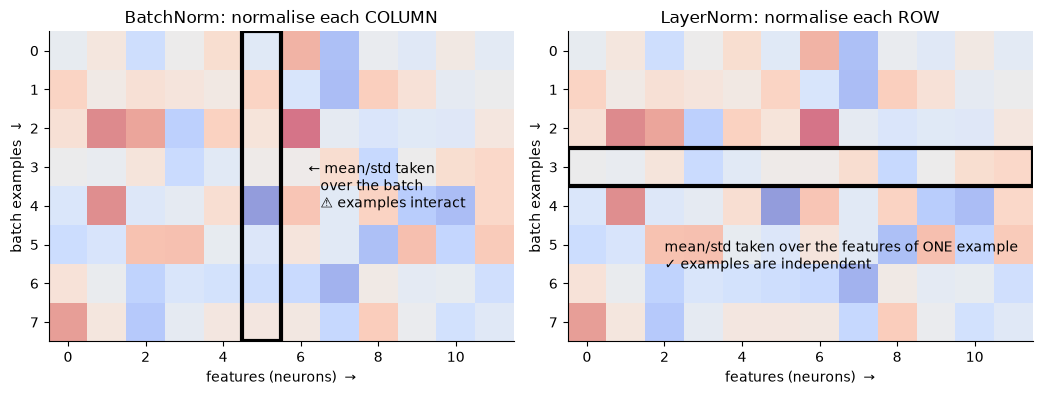

In [14]:
from matplotlib.patches import Rectangle
torch.manual_seed(3)
M = torch.randn(8, 12)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for a, kind in zip(ax, ['BatchNorm: normalise each COLUMN', 'LayerNorm: normalise each ROW']):
    a.imshow(M, cmap='coolwarm', alpha=.55); a.grid(False)
    a.set_xlabel('features (neurons)  →'); a.set_ylabel('batch examples  ↓'); a.set_title(kind)
ax[0].add_patch(Rectangle((4.5, -.5), 1, 8, fill=False, ec='black', lw=3))
ax[0].text(6.2, 3.5, '← mean/std taken\n   over the batch\n   ⚠ examples interact', va='center')
ax[1].add_patch(Rectangle((-.5, 2.5), 12, 1, fill=False, ec='black', lw=3))
ax[1].text(2, 5.3, 'mean/std taken over the features of ONE example\n✓ examples are independent', va='center')
plt.tight_layout(); plt.show()

###  Verify: after BN every neuron has mean 0 and std 1, whatever it looked like before

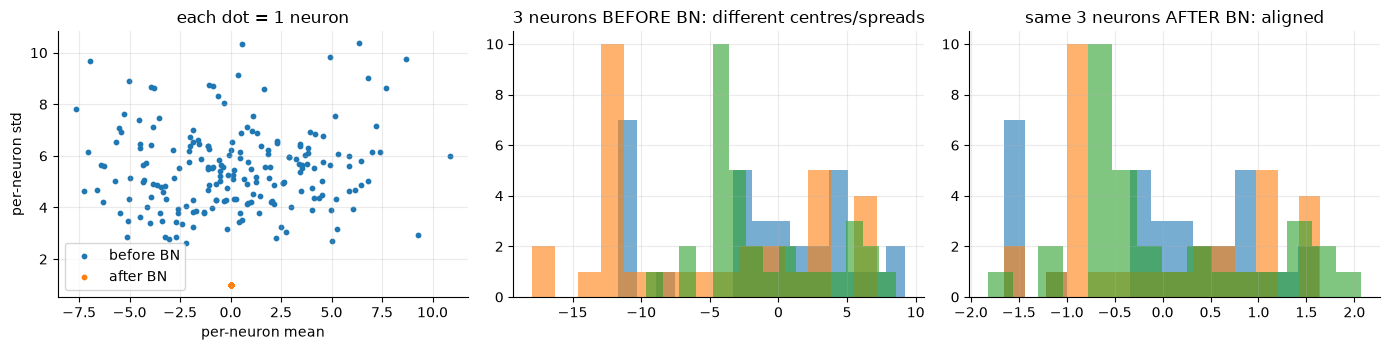

before: mean range [-7.6, 10.8], std range [2.6, 10.4]
after : mean range [-2.7e-07, 1.5e-07], std range [1.000, 1.000]
with γ=2, β=1 the dials shift it to: mean 1.00, std 1.97


In [15]:
W1_big = torch.randn(n_embd * block_size, n_hidden) * 1.0     # deliberately sloppy init
hpre = embcat_fixed @ W1_big + torch.randn(n_hidden) * 3       # + random per-neuron offsets
bnmean = hpre.mean(0, keepdim=True)
bnstd  = hpre.std(0, keepdim=True)
hbn = (hpre - bnmean) / bnstd

fig, ax = plt.subplots(1, 3, figsize=(14, 3.6))
ax[0].scatter(hpre.mean(0), hpre.std(0), s=10, label='before BN'); ax[0].scatter(hbn.mean(0), hbn.std(0), s=10, label='after BN')
ax[0].set_xlabel('per-neuron mean'); ax[0].set_ylabel('per-neuron std'); ax[0].legend(); ax[0].set_title('each dot = 1 neuron')
for j, c in zip([0, 1, 2], ['C0', 'C1', 'C2']):
    ax[1].hist(hpre[:, j], bins=15, alpha=.6, color=c)
    ax[2].hist(hbn[:, j],  bins=15, alpha=.6, color=c)
ax[1].set_title('3 neurons BEFORE BN: different centres/spreads'); ax[2].set_title('same 3 neurons AFTER BN: aligned')
plt.tight_layout(); plt.show()
print('before: mean range [%.1f, %.1f], std range [%.1f, %.1f]' % (hpre.mean(0).min(), hpre.mean(0).max(), hpre.std(0).min(), hpre.std(0).max()))
print('after : mean range [%.1e, %.1e], std range [%.3f, %.3f]' % (hbn.mean(0).min(), hbn.mean(0).max(), hbn.std(0).min(), hbn.std(0).max()))

gamma, beta = 2.0, 1.0
y = gamma * hbn + beta
print(f'with γ=2, β=1 the dials shift it to: mean {y.mean():.2f}, std {y.std():.2f}')

###  Why BN makes `W1`'s scale (and the bias `b1`) irrelevant
* **Scale-invariance:** if you multiply all pre-activations by 10, the moderator divides by a std that's also 10× bigger → the output is identical.
* **Bias is useless before BN:** adding a constant to a column shifts the mean by that constant, and BN subtracts the mean right back out. That's why the lecture **deletes `b1`** and lets BN's β do that job.

In [16]:
def bn(h, eps=1e-5): return (h - h.mean(0, keepdim=True)) / torch.sqrt(h.var(0, keepdim=True) + eps)
base = bn(hpre)
print('x10 pre-activations -> same output? ', torch.allclose(bn(hpre * 10), base, atol=1e-4))
print('+ random bias b1    -> same output? ', torch.allclose(bn(hpre + torch.randn(n_hidden) * 5), base, atol=1e-4))

x10 pre-activations -> same output?  True
+ random bias b1    -> same output?  True


### ⚠️ The price: examples are now *coupled*
Without BN, example #0's output depends only on example #0. With BN it depends on **who else is in the batch** (they set the mean and std). That's (a) a hidden source of bugs, (b) the reason BN is a mild *regulariser* (each example gets slightly jittered by its batch-mates, like data augmentation), and (c) why people moved to LayerNorm/GroupNorm.
### 🔬 Same example, two different batches

max |difference| for the SAME example: 0.9393348693847656


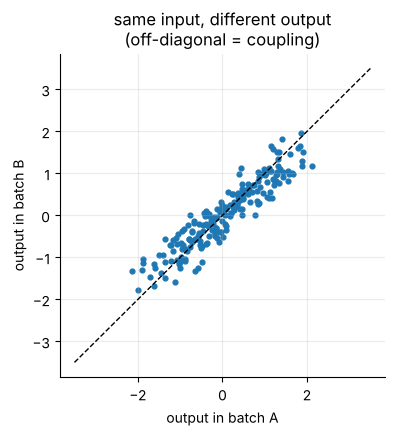

In [20]:
torch.manual_seed(7)
ix_all = torch.randint(0, Xtr.shape[0], (64,))
hp_all = Cemb[Xtr[ix_all]].view(64, -1) @ (torch.randn(30, 200) * 0.3)

batch_A = hp_all[:32]                                  # example 0 + 31 buddies
batch_B = torch.cat([hp_all[:1], hp_all[32:63]])       # example 0 + 31 DIFFERENT buddies
outA, outB = bn(batch_A)[0], bn(batch_B)[0]
print('max |difference| for the SAME example:', (outA - outB).abs().max().item())

plt.figure(figsize=(4.2, 4.2)); plt.scatter(outA, outB, s=12); lim = [-3.5, 3.5]; plt.plot(lim, lim, 'k--', lw=1)
plt.xlabel('output in batch A'); plt.ylabel('output in batch B'); plt.title('same input, different output\n(off-diagonal = coupling)'); plt.show()

### Inference: nobody hands you a batch — use **running statistics**
At test time you may have a single example (std of 1 sample = undefined!). Solution: during training keep an **exponential moving average** of each batch's mean/std, then use those frozen numbers at inference.

$$\text{running} \leftarrow (1-m)\cdot\text{running} + m\cdot\text{batch stat}$$

`m` (momentum) trades **noise** vs **lag**: big `m` follows the weights quickly but jitters; tiny `m` is smooth but slow. (Lecture uses 0.001 because batch=32 is noisy; PyTorch's default is 0.1.)
Alternative: after training, do one pass over the training set and compute the exact mean/std (**"calibration"**) — we do that in §5.
### 👀 EMA with different momentum vs. the true full-data mean (weights frozen, one neuron)

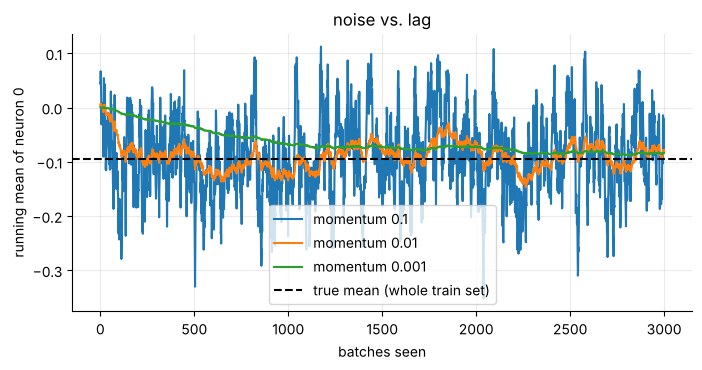

In [21]:
torch.manual_seed(1)
Wfix = torch.randn(30, 200) * 0.3
true_mean = (Cemb[Xtr].view(len(Xtr), -1) @ Wfix).mean(0)[0].item()        # exact mean of neuron 0 over the training set
runs = {0.1: 0.0, 0.01: 0.0, 0.001: 0.0}
trace = {m: [] for m in runs}
for step in range(3000):
    ix = torch.randint(0, Xtr.shape[0], (32,))
    b = (Cemb[Xtr[ix]].view(32, -1) @ Wfix)[:, 0].mean().item()
    for m in runs:
        runs[m] = (1 - m) * runs[m] + m * b; trace[m].append(runs[m])
plt.figure(figsize=(8, 3.6))
for m in trace: plt.plot(trace[m], label=f'momentum {m}')
plt.axhline(true_mean, color='k', ls='--', label='true mean (whole train set)')
plt.xlabel('batches seen'); plt.ylabel('running mean of neuron 0'); plt.legend(); plt.title('noise vs. lag'); plt.show()

### 🔬 Bonus: at inference, BN can be *fused away* into the preceding Linear layer
Because at test time BN is just "subtract a constant, divide by a constant, scale, shift" — an affine map — it merges into `W, b`:

$$W' = W\cdot\frac{\gamma}{\sqrt{\sigma^2+\varepsilon}}\qquad b' = (b-\mu)\frac{\gamma}{\sqrt{\sigma^2+\varepsilon}}+\beta$$

(That was one of the lecture's suggested exercises.)

In [22]:
torch.manual_seed(0)
W = torch.randn(30, 200) * 0.3;  b = torch.randn(200) * 0.1
gam, bet = torch.rand(200) + 0.5, torch.randn(200) * 0.1
xs = Cemb[Xtr[:5000]].view(5000, -1)
mu, var = (xs @ W + b).mean(0), (xs @ W + b).var(0); eps = 1e-5

def lin_then_bn_eval(x): return gam * ((x @ W + b - mu) / torch.sqrt(var + eps)) + bet
s = gam / torch.sqrt(var + eps)
W_fused, b_fused = W * s, (b - mu) * s + bet
x_new = Cemb[Xdev[:100]].view(100, -1)
print('fused == unfused ?', torch.allclose(lin_then_bn_eval(x_new), x_new @ W_fused + b_fused, atol=1e-5))

fused == unfused ? True


### Small details worth remembering
* **std vs var, biased vs unbiased:** the BN paper normalises with the *biased* variance in training but uses the *unbiased* one for running stats — a tiny train/test mismatch. Lecture's view: just use unbiased (`÷(m−1)`) everywhere.
* **Where to put it:** after `Linear`/`Conv`, *before* the non-linearity (as in the lecture). Plenty of modern nets still do this.
* **What BN does *not* do:** it doesn't magically fix a bad *last-layer* init, so the output layer still gets a small gain (`γ *= 0.1`) in §7.
* **Alternatives:** LayerNorm, GroupNorm, RMSNorm → no batch coupling, work at batch size 1. The lecture's advice: BN works, but "try to stay away from it" if you can.

---
## 5 · Put it together: the real model with BatchNorm

This is the lecture notebook's code: init fixes from §1–§3 + BatchNorm between `Linear` and `tanh`. Note:
* `b1` is **gone** (BN's β replaces it),
* `W1` uses Kaiming: `(5/3)/√(n_embd·block_size)`,
* `W2 *= 0.01`, `b2 = 0` (§1),
* running mean/std updated with `momentum = 0.001` under `torch.no_grad()`.

In [23]:
g = torch.Generator().manual_seed(2147483647)
C  = torch.randn((vocab_size, n_embd), generator=g)
W1 = torch.randn((n_embd * block_size, n_hidden), generator=g) * (5/3) / ((n_embd * block_size) ** 0.5)
W2 = torch.randn((n_hidden, vocab_size), generator=g) * 0.01
b2 = torch.zeros(vocab_size)

bngain = torch.ones((1, n_hidden)); bnbias = torch.zeros((1, n_hidden))
bnmean_running = torch.zeros((1, n_hidden)); bnstd_running = torch.ones((1, n_hidden))

parameters = [C, W1, W2, b2, bngain, bnbias]
print('parameters:', sum(p.nelement() for p in parameters))
for p in parameters: p.requires_grad = True

parameters: 12097


In [24]:
max_steps, batch_size = 200_000, 32          # lower max_steps (e.g. 20_000) for a quick run
lossi = []
t0 = time.time()
for i in range(max_steps):
    # minibatch
    ix = torch.randint(0, Xtr.shape[0], (batch_size,), generator=g)
    Xb, Yb = Xtr[ix], Ytr[ix]

    # forward
    emb = C[Xb]
    embcat = emb.view(emb.shape[0], -1)
    hpreact = embcat @ W1                                           # Linear (no bias!)
    bnmeani = hpreact.mean(0, keepdim=True)                         # ── BatchNorm ──
    bnstdi  = hpreact.std(0, keepdim=True)
    hpreact = bngain * (hpreact - bnmeani) / bnstdi + bnbias
    with torch.no_grad():
        bnmean_running = 0.999 * bnmean_running + 0.001 * bnmeani
        bnstd_running  = 0.999 * bnstd_running  + 0.001 * bnstdi    # ───────────────
    h = torch.tanh(hpreact)                                         # non-linearity
    logits = h @ W2 + b2
    loss = F.cross_entropy(logits, Yb)

    # backward + SGD with step decay
    for p in parameters: p.grad = None
    loss.backward()
    lr = 0.1 if i < 100_000 else 0.01
    for p in parameters: p.data += -lr * p.grad

    if i % 20_000 == 0: print(f'{i:7d}/{max_steps:7d}: {loss.item():.4f}')
    lossi.append(loss.log10().item())
print(f'done in {time.time() - t0:.0f}s')

      0/ 200000: 3.3195


  20000/ 200000: 2.3325


  40000/ 200000: 2.1420


  60000/ 200000: 2.0658


  80000/ 200000: 1.7567


 100000/ 200000: 1.9758


 120000/ 200000: 2.2282


 140000/ 200000: 2.0277


 160000/ 200000: 2.1316


 180000/ 200000: 1.8789


done in 123s


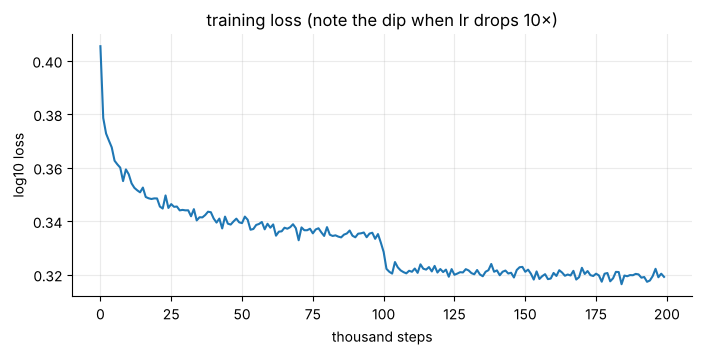

In [25]:
plt.figure(figsize=(8, 3.4))
plt.plot(torch.tensor(lossi).view(-1, 1000).mean(1))          # average every 1000 steps
plt.xlabel('thousand steps'); plt.ylabel('log10 loss'); plt.title('training loss (note the dip when lr drops 10×)'); plt.show()

### 🔬 Evaluate: running stats vs. calibrated stats

In [26]:
# calibration: exact mean/std of the pre-activations over the whole training set
with torch.no_grad():
    emb = C[Xtr]; embcat = emb.view(emb.shape[0], -1)
    hpreact = embcat @ W1
    bnmean_cal, bnstd_cal = hpreact.mean(0, keepdim=True), hpreact.std(0, keepdim=True)
print('max |running_mean - calibrated_mean| =', (bnmean_running - bnmean_cal).abs().max().item())
print('max |running_std  - calibrated_std | =', (bnstd_running  - bnstd_cal ).abs().max().item())

@torch.no_grad()
def split_loss(split, mean, std):
    x, y = {'train': (Xtr, Ytr), 'val': (Xdev, Ydev), 'test': (Xte, Yte)}[split]
    emb = C[x]; embcat = emb.view(emb.shape[0], -1)
    hpreact = embcat @ W1
    hpreact = bngain * (hpreact - mean) / std + bnbias
    logits = torch.tanh(hpreact) @ W2 + b2
    return F.cross_entropy(logits, y).item()

for name, (m_, s_) in {'running': (bnmean_running, bnstd_running), 'calibrated': (bnmean_cal, bnstd_cal)}.items():
    print(f'{name:>10}:  train {split_loss("train", m_, s_):.4f}   val {split_loss("val", m_, s_):.4f}')

max |running_mean - calibrated_mean| = 0.02787458896636963
max |running_std  - calibrated_std | = 0.05266118049621582


   running:  train 2.0672   val 2.1067


calibrated:  train 2.0675   val 2.1066


**Reading it.** Train ≈ 2.067, val ≈ 2.107. (The lecture quotes Part 2's model at ≈ 2.17 and ≈ 2.13 after the init fixes alone: the gain here comes from *not wasting optimisation steps*, not from a bigger model.) Don't over-credit BN: for a 1-hidden-layer net it isn't needed — its payoff shows up in **deeper** nets (§7). Calibrated and running stats agree to ~3 decimals, so the EMA is a faithful stand-in for "the true statistics".

### Sample some names

In [27]:
g2 = torch.Generator().manual_seed(2147483647 + 10)
for _ in range(15):
    out, context = [], [0] * block_size
    while True:
        emb = C[torch.tensor([context])]
        hpreact = bngain * (emb.view(1, -1) @ W1 - bnmean_running) / bnstd_running + bnbias
        probs = F.softmax(torch.tanh(hpreact) @ W2 + b2, dim=1)
        ix = torch.multinomial(probs, num_samples=1, generator=g2).item()
        context = context[1:] + [ix]; out.append(ix)
        if ix == 0: break
    print(''.join(itos[i] for i in out))

carmah.
amori.
kifregrachelly.
salaysie.
mahnee.
delynn.
jareei.
nellara.
chaiir.
kaleigh.
ham.
join.
quinthoron.
marianni.
waythogiearynix.


---
## 6 · PyTorch-ify the code: `Linear`, `BatchNorm1d`, `Tanh`

### 🧒 ELI5
So far we've been hand-wiring every pipe. Better: build **LEGO bricks** — each brick takes a tensor in, hands a tensor out, and knows its own parameters. Then a deep net is just a **list of bricks** and the forward pass is a `for` loop. The bricks mirror `torch.nn` so the knowledge transfers 1:1.

```
 x ─► [Linear] ─► [BatchNorm1d] ─► [Tanh] ─► [Linear] ─► [BatchNorm1d] ─► [Tanh] ─► ... ─► [Linear] ─► [BatchNorm1d] ─► logits
        W            γ, β, running stats                W         γ, β                                  W           γ(×0.1)
```
Two details that make a brick trustworthy:
* `BatchNorm1d` has a **`training` flag** – batch stats when training, running stats when evaluating (forget `.eval()` and your test numbers will be quietly wrong).
* Each brick stores `self.out` – so we can later *look inside* the network (§7).

In [28]:
class Linear:
    def __init__(self, fan_in, fan_out, bias=True, g=None):
        self.weight = torch.randn((fan_in, fan_out), generator=g) / fan_in**0.5     # Kaiming w/ gain 1
        self.bias = torch.zeros(fan_out) if bias else None
    def __call__(self, x):
        self.out = x @ self.weight
        if self.bias is not None: self.out += self.bias
        return self.out
    def parameters(self):
        return [self.weight] + ([] if self.bias is None else [self.bias])

class BatchNorm1d:
    def __init__(self, dim, eps=1e-5, momentum=0.1):
        self.eps, self.momentum, self.training = eps, momentum, True
        self.gamma, self.beta = torch.ones(dim), torch.zeros(dim)            # trained with backprop
        self.running_mean, self.running_var = torch.zeros(dim), torch.ones(dim)   # trained with EMA
    def __call__(self, x):
        if self.training:
            xmean, xvar = x.mean(0, keepdim=True), x.var(0, keepdim=True)
        else:
            xmean, xvar = self.running_mean, self.running_var
        xhat = (x - xmean) / torch.sqrt(xvar + self.eps)
        self.out = self.gamma * xhat + self.beta
        if self.training:
            with torch.no_grad():
                self.running_mean = (1 - self.momentum) * self.running_mean + self.momentum * xmean
                self.running_var  = (1 - self.momentum) * self.running_var  + self.momentum * xvar
        return self.out
    def parameters(self): return [self.gamma, self.beta]

class Tanh:
    def __call__(self, x):
        self.out = torch.tanh(x); return self.out
    def parameters(self): return []

### A configurable deep net + training loop that **records vitals**
`make_net(...)` builds *embedding → 5 × (Linear → [BN] → Tanh) → Linear → [BN]*.
The training loop additionally keeps:
* `layer.out.retain_grad()` → so we can look at **gradients flowing through each layer**,
* an **update-to-data ratio** per parameter at each step: $\log_{10}\dfrac{\text{std}(\text{lr}\cdot\text{grad})}{\text{std}(\text{param})}$.

In [29]:
def make_net(use_bn=False, gain=5/3, n_hidden=100, depth=5, seed=2147483647):
    g = torch.Generator().manual_seed(seed)
    C = torch.randn((vocab_size, n_embd), generator=g)
    layers, fan_in = [], n_embd * block_size
    for _ in range(depth):
        layers.append(Linear(fan_in, n_hidden, bias=False, g=g))
        if use_bn: layers.append(BatchNorm1d(n_hidden))
        layers.append(Tanh())
        fan_in = n_hidden
    layers.append(Linear(fan_in, vocab_size, bias=False, g=g))
    if use_bn: layers.append(BatchNorm1d(vocab_size))
    with torch.no_grad():
        if use_bn: layers[-1].gamma *= 0.1          # last layer: make it less confident (§1)
        else:      layers[-1].weight *= 0.1
        for layer in layers[:-1]:
            if isinstance(layer, Linear): layer.weight *= gain          # tanh gain (§3)
    parameters = [C] + [p for layer in layers for p in layer.parameters()]
    for p in parameters: p.requires_grad = True
    return dict(C=C, layers=layers, parameters=parameters, g=g)

def train_net(net, steps=2000, lr=0.1, batch_size=32):
    C, layers, parameters, g = net['C'], net['layers'], net['parameters'], net['g']
    lossi, ud = [], []
    for i in range(steps):
        ix = torch.randint(0, Xtr.shape[0], (batch_size,), generator=g)
        Xb, Yb = Xtr[ix], Ytr[ix]
        x = C[Xb].view(batch_size, -1)
        for layer in layers: x = layer(x)
        loss = F.cross_entropy(x, Yb)
        for layer in layers: layer.out.retain_grad()               # keep dL/d(out) for plotting
        for p in parameters: p.grad = None
        loss.backward()
        for p in parameters: p.data += -lr * p.grad
        lossi.append(loss.item())
        with torch.no_grad():
            ud.append([((lr * p.grad).std() / p.data.std()).log10().item() for p in parameters])
    net.update(lossi=lossi, ud=ud)
    return net

### Sanity check: the pieces behave like `torch.nn`
(One honest wrinkle: PyTorch normalises a batch with the *biased* variance, the lecture's brick with the *unbiased* one — a ~0.8 % scale difference at batch size 64. It's the same "std vs var" detail mentioned in §4.)

In [30]:
x = torch.randn(64, 30)
mine = BatchNorm1d(30); theirs = torch.nn.BatchNorm1d(30, eps=1e-5, momentum=0.1)
out_m, out_t = mine(x), theirs(x)
print('train mode, raw                 :', torch.allclose(out_m, out_t, atol=1e-5), f'(max diff {(out_m - out_t).abs().max():.4f})')
# torch normalises with the BIASED variance (÷m); the lecture's brick uses unbiased (÷(m-1)). Correct for it:
print('train mode, after ×√(m/(m−1))   :', torch.allclose(out_m * (64 / 63) ** 0.5, out_t, atol=1e-5))
mine.training = False; theirs.eval()
print('eval mode (running stats)       :', torch.allclose(mine(x), theirs(x), atol=1e-4))

train mode, raw                 : False (max diff 0.0275)
train mode, after ×√(m/(m−1))   : True
eval mode (running stats)       : True


---
## 7 · Diagnostics: a volume meter on every layer

### 🧒 ELI5 — a doctor's check-up for your network
| vital sign | what we measure | healthy | in the whisper-chain |
|---|---|---|---|
| **Forward activations** | histogram, mean, std, % saturated of each `tanh` output | same shape in every layer, saturation ≲ 5 % | everyone hears the message at the same volume |
| **Backward gradients** | histogram of `dL/d(out)` per layer | same width in every layer | the corrections shouted back are equally loud at every position |
| **Weight gradients** | histogram of `dL/dW` | no layer wildly bigger/smaller | nobody is being yelled at 100× more than their neighbours |
| **Update : data ratio** | $\log_{10}$( std(lr·grad) / std(param) ) over time | ≈ **−3** (params move ~0.1 % of their size per step) | a plant should grow ~0.1 % per day; 10 %/day = it will pop, 0.0001 %/day = it's dead |

The "−3" line is a **rule of thumb**, not a law: below it (e.g. −5) → learning rate too low / params not moving; far above (e.g. −1) → too high / unstable.

🎬 **Watch (conceptual):** what "gradients" are and why their *size per layer* matters — [3Blue1Brown, backprop intuition](https://www.youtube.com/watch?v=Ilg3gGewQ5U) (video from §2 — rewatch the "sensitivity of the cost to each weight" part).

In [31]:
def diagnose(net, title, hist_bins=40):
    layers, parameters, ud = net['layers'], net['parameters'], net['ud']
    tanh_layers = [l for l in layers[:-1] if isinstance(l, Tanh)]
    fig, ax = plt.subplots(1, 4, figsize=(19, 3.8))

    # 1) forward activations
    for i, l in enumerate(tanh_layers):
        t = l.out; hy, hx = torch.histogram(t.detach().flatten(), bins=hist_bins, range=(-1, 1), density=True)
        ax[0].plot(hx[:-1], hy, label=f'L{i}  mean {t.mean():+.2f}  std {t.std():.2f}  sat {(t.abs() > 0.97).float().mean()*100:.0f}%')
    ax[0].set_title('activation distribution (tanh outputs)'); ax[0].legend(fontsize=7)

    # 2) backward gradients at the tanh outputs
    lim = 4 * max(l.out.grad.std().item() for l in tanh_layers)
    for i, l in enumerate(tanh_layers):
        t = l.out.grad; hy, hx = torch.histogram(t.detach().flatten(), bins=hist_bins, range=(-lim, lim), density=True)
        ax[1].plot(hx[:-1], hy, label=f'L{i}  std {t.std():.1e}')
    ax[1].set_title('gradient distribution (dL/d tanh-out)'); ax[1].legend(fontsize=7)

    # 3) weight gradients
    ws = [p for p in parameters if p.ndim == 2 and p.shape[1] != 10]
    lim = 4 * max(p.grad.std().item() for p in ws)
    for i, p in enumerate(ws):
        hy, hx = torch.histogram(p.grad.detach().flatten(), bins=hist_bins, range=(-lim, lim), density=True)
        ax[2].plot(hx[:-1], hy, label=f'W{i} {tuple(p.shape)}  grad:data {p.grad.std()/p.std():.0e}')
    ax[2].set_title('weight-gradient distribution'); ax[2].legend(fontsize=7)

    # 4) update:data ratio over time
    for i, p in enumerate(parameters):
        if p.ndim == 2: ax[3].plot([u[i] for u in ud], label=f'{tuple(p.shape)}')
    ax[3].axhline(-3, color='k', ls='--', lw=1); ax[3].set_title('update : data ratio  (log10)  — target ≈ −3')
    ax[3].legend(fontsize=7, ncol=2)
    fig.suptitle(title, y=1.03, fontweight='bold'); plt.tight_layout(); plt.show()

def summary(net, name):
    ls = net['lossi']; tl = [l for l in net['layers'][:-1] if isinstance(l, Tanh)]
    sat = [(l.out.abs() > 0.97).float().mean().item() * 100 for l in tl]
    gstd = [l.out.grad.std().item() for l in tl]
    print(f"{name:<26} loss(last200)={np.mean(ls[-200:]):.3f}  | act std L0→L4: {[round(l.out.std().item(), 2) for l in tl]}"
          f"  | sat%: {[round(s) for s in sat]}  | grad std L0/L4 = {gstd[0]/gstd[-1]:.2f}")

### 🔬 Experiment A — the gain knob (no BatchNorm), 5 tanh layers, 2000 steps
Same net, three different `gain`s. Predict before you run: which one has the *flat* profile across layers?

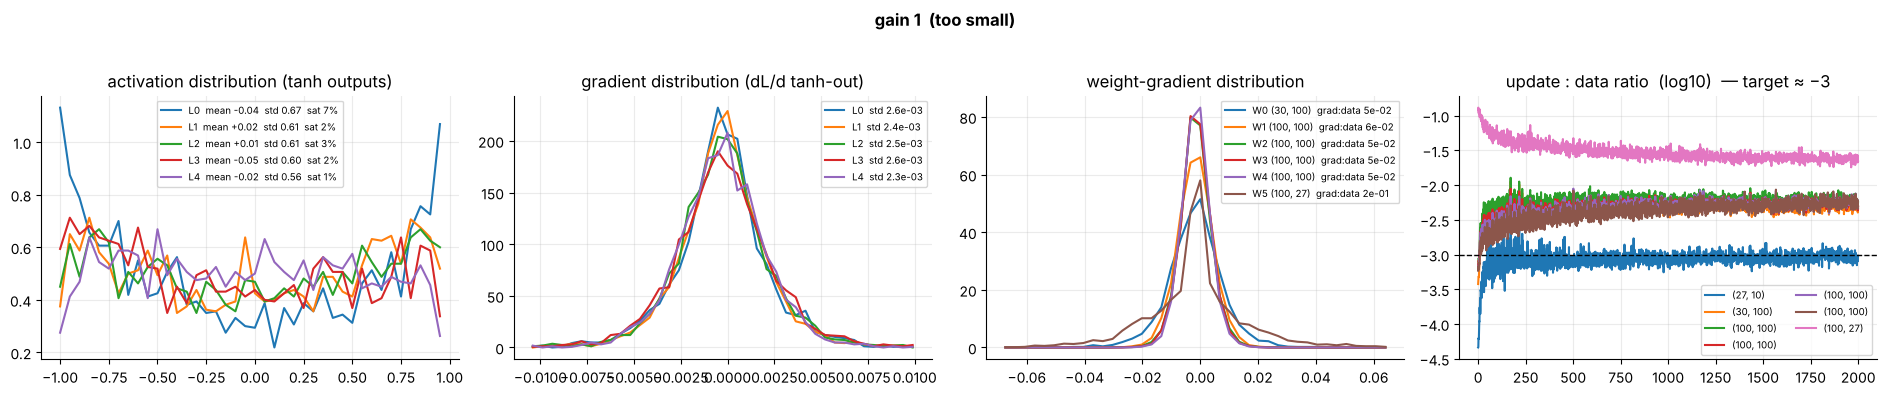

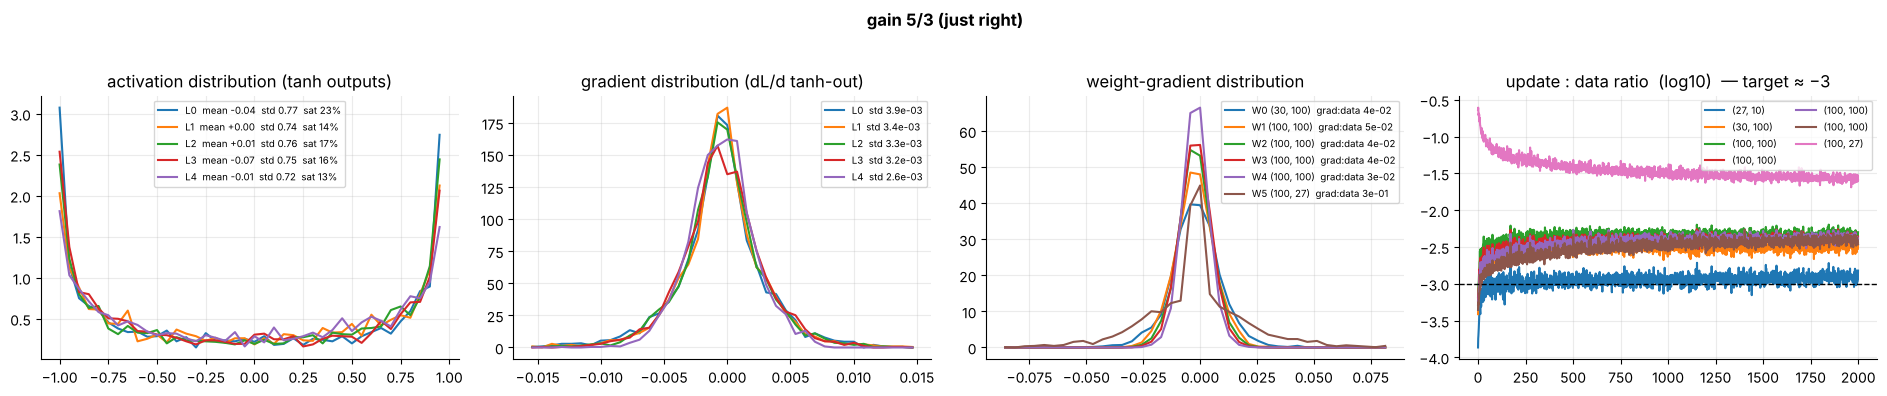

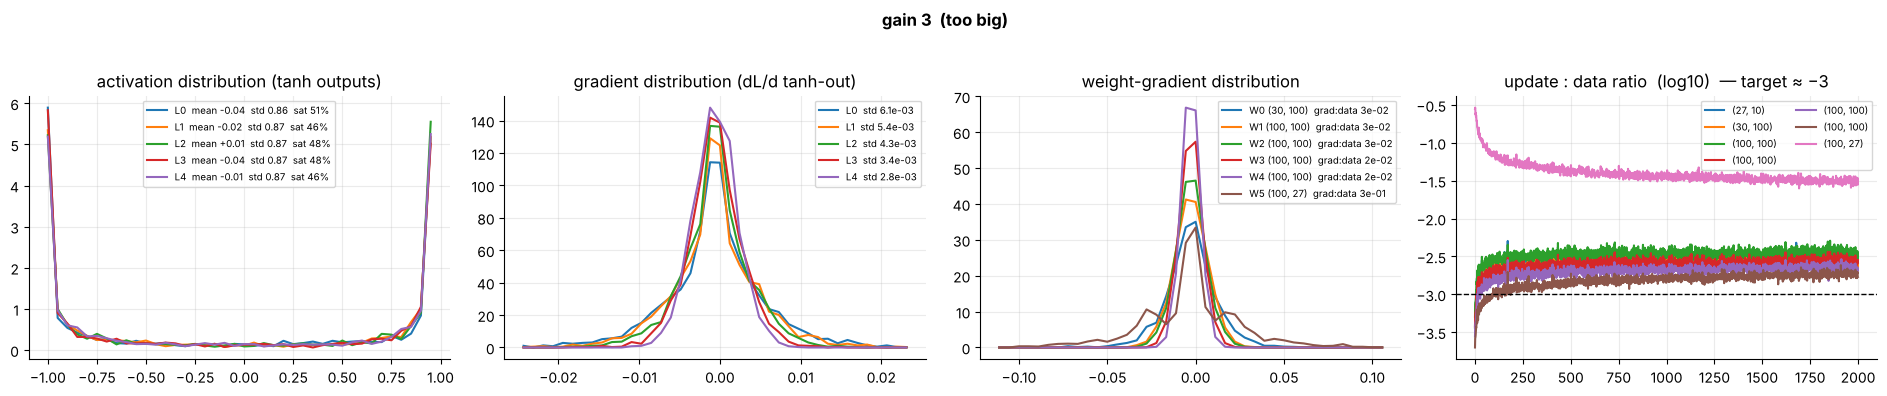

gain 1  (too small)        loss(last200)=2.346  | act std L0→L4: [0.67, 0.61, 0.61, 0.6, 0.56]  | sat%: [7, 2, 3, 2, 1]  | grad std L0/L4 = 1.11
gain 5/3 (just right)      loss(last200)=2.292  | act std L0→L4: [0.77, 0.74, 0.76, 0.75, 0.72]  | sat%: [23, 14, 17, 16, 13]  | grad std L0/L4 = 1.50
gain 3  (too big)          loss(last200)=2.335  | act std L0→L4: [0.86, 0.87, 0.87, 0.87, 0.87]  | sat%: [51, 46, 48, 48, 46]  | grad std L0/L4 = 2.20


In [32]:
nets = {}
for name, gain in [('gain 1  (too small)', 1.0), ('gain 5/3 (just right)', 5/3), ('gain 3  (too big)', 3.0)]:
    nets[name] = train_net(make_net(use_bn=False, gain=gain), steps=2000, lr=0.1)
    diagnose(nets[name], name)
for name, net in nets.items(): summary(net, name)

**How to read the four panels (this is the skill the lecture is really teaching):**

* **gain 3 (too big):** activations pile up at ±1 — saturation is ≈ 46–51 % in *every* layer. That's the unmistakable signature.
* **gain 5/3:** activation std ≈ 0.75 in every layer, saturation ≈ 13–23 % (the first layer is highest because its inputs are raw embeddings). Flat profile across layers = healthy.
* **gain 1 (too small):** saturation is only ≈ 1–7 % and the std drifts down a little with depth (0.67 → 0.56). Mild here, because 5 layers is shallow.
* In all three, the gradient histograms overlap across layers: **vanishing/exploding gradients are not visible in a 5-layer net**, and the final losses (≈ 2.29–2.35, single seed) are close. *Read the vitals, not the loss* — and make the net deeper to see the failure (next cell).

### 🔬 Experiment A2 — same test, 20 layers deep
Depth amplifies every per-layer error (the photocopier chain of §3). Printing layers 0, 5, 10, 15, 19:

In [33]:
idx = [0, 5, 10, 15, 19]
for gain in [1.0, 5/3, 3.0]:
    n = train_net(make_net(use_bn=False, gain=gain, depth=20), steps=1000, lr=0.1)
    tl = [l for l in n['layers'][:-1] if isinstance(l, Tanh)]
    print(f'gain {gain:.2f}  loss {np.mean(n["lossi"][-200:]):.3f} | act std {[round(tl[i].out.std().item(), 2) for i in idx]}'
          f' | sat% {[round((tl[i].out.abs() > .97).float().mean().item() * 100) for i in idx]}'
          f' | grad std {["%.0e" % tl[i].out.grad.std().item() for i in idx]}')

gain 1.00  loss 2.525 | act std [0.63, 0.48, 0.51, 0.54, 0.51] | sat% [5, 0, 0, 0, 1] | grad std ['1e-03', '8e-04', '8e-04', '9e-04', '2e-03']


gain 1.67  loss 2.493 | act std [0.76, 0.74, 0.76, 0.76, 0.69] | sat% [23, 16, 17, 14, 10] | grad std ['4e-03', '2e-03', '2e-03', '2e-03', '2e-03']


gain 3.00  loss 2.814 | act std [0.94, 0.95, 0.92, 0.92, 0.83] | sat% [74, 78, 67, 66, 38] | grad std ['2e-03', '1e-03', '2e-03', '2e-03', '1e-03']


**Reading it.** At depth 20, gain 3 is 66–78 % saturated through most of the stack and its loss is clearly worse than the other two. Gain 1 *still trains* — because the weights keep learning, the net partly repairs a bad start (its activation std settles around 0.5) — but a bad gain costs you speed and wastes steps; it's cheapest to fix at init.

### 🔬 Experiment B — the same sweep **with BatchNorm**
Now the gain barely changes the *forward* statistics. Does it matter at all?

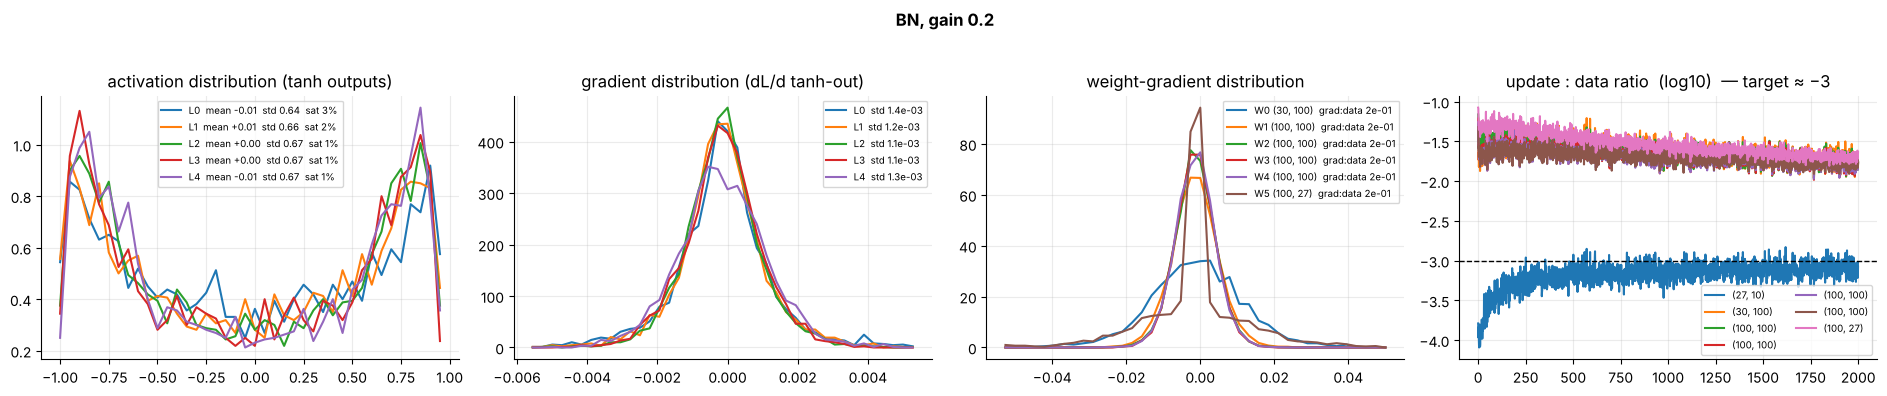

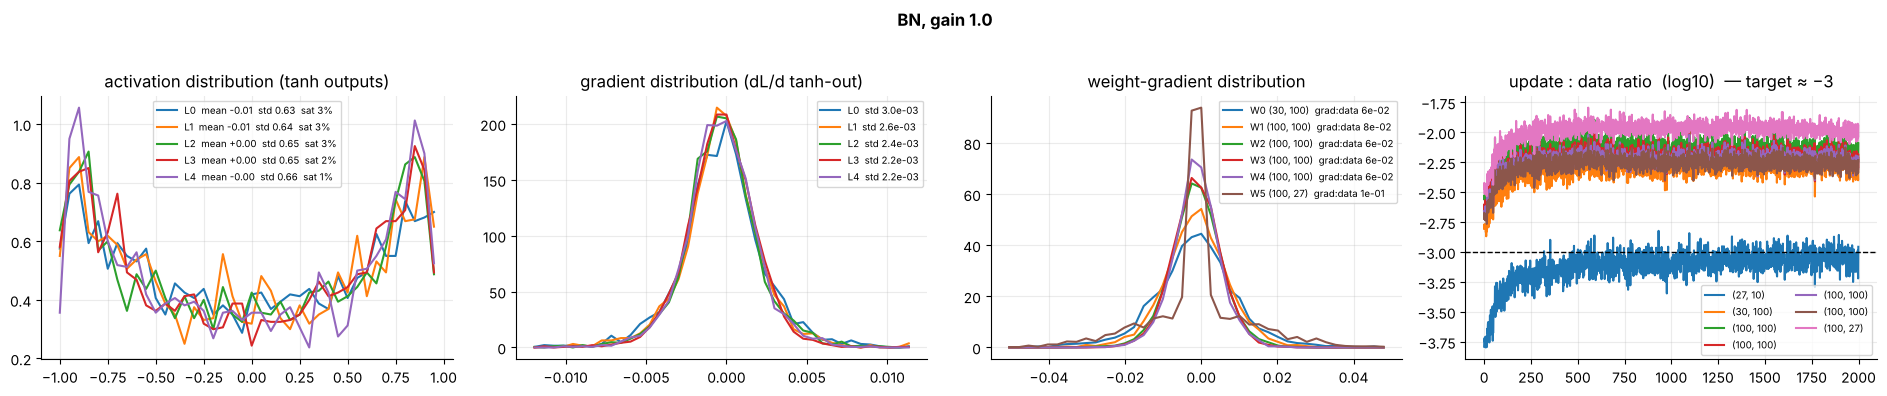

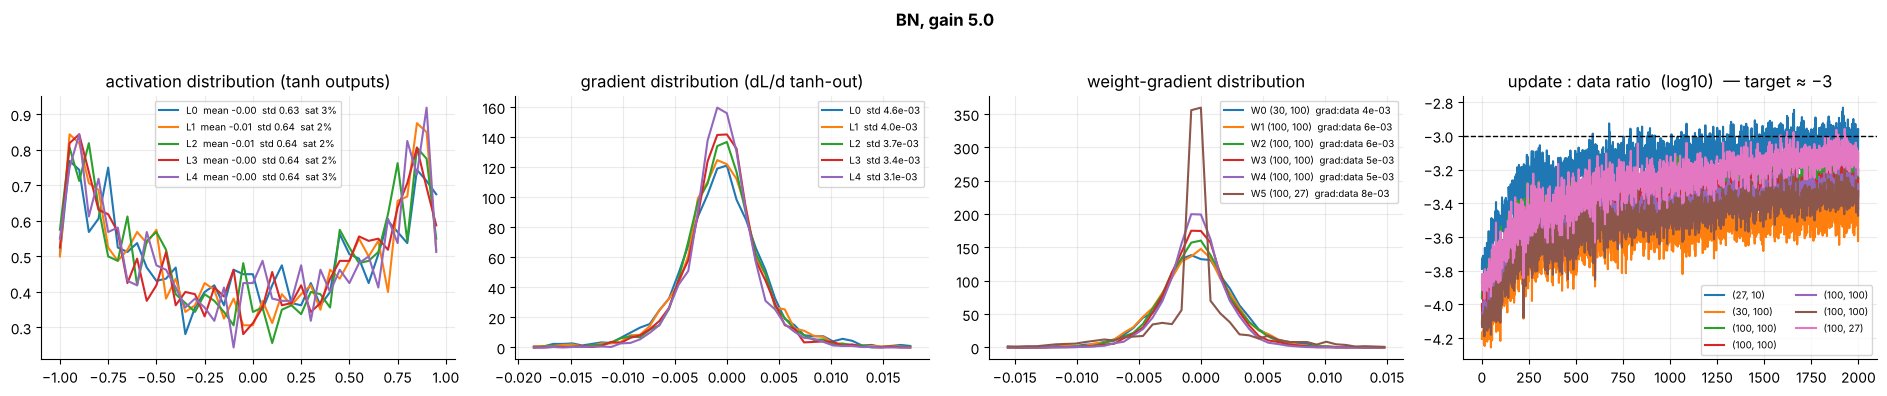

BN, gain 0.2               loss(last200)=2.399  | act std L0→L4: [0.64, 0.66, 0.67, 0.67, 0.67]  | sat%: [3, 2, 1, 1, 1]  | grad std L0/L4 = 1.11
BN, gain 1.0               loss(last200)=2.366  | act std L0→L4: [0.63, 0.64, 0.65, 0.65, 0.66]  | sat%: [3, 3, 3, 2, 1]  | grad std L0/L4 = 1.36
BN, gain 5.0               loss(last200)=2.533  | act std L0→L4: [0.63, 0.64, 0.64, 0.64, 0.64]  | sat%: [3, 3, 2, 2, 3]  | grad std L0/L4 = 1.48


In [34]:
bn_nets = {}
for gain in [0.2, 1.0, 5.0]:
    name = f'BN, gain {gain}'
    bn_nets[name] = train_net(make_net(use_bn=True, gain=gain), steps=2000, lr=0.1)
    diagnose(bn_nets[name], name)
for name, net in bn_nets.items(): summary(net, name)

In [35]:
print('mean update:data ratio (log10) of the FIRST weight matrix over the last 500 steps:')
for name, net in bn_nets.items():
    i_w = 1                                    # index 0 is C (embedding), index 1 is the first Linear weight
    print(f'  {name:<14} {np.mean([u[i_w] for u in net["ud"][-500:]]):+.2f}')

mean update:data ratio (log10) of the FIRST weight matrix over the last 500 steps:
  BN, gain 0.2   -1.72
  BN, gain 1.0   -2.27
  BN, gain 5.0   -3.49


**What BN gives you, and what it doesn't:**
* ✅ Forward activations are healthy for *every* gain (BN re-centres them) → the net is much **less sensitive to init** (the scale-invariance from §4).
* ⚠️ But the **update:data ratio still depends on the weight scale**: with a big gain the weights are large, so the *same* `lr` is a *relatively smaller* step; with a tiny gain the same `lr` is a *relatively huge* step. Measured above: log10 ratio ≈ −1.7 (gain 0.2) → −2.3 (gain 1) → −3.5 (gain 5), and the gain-5 net is the slowest learner (loss ≈ 2.53 vs ≈ 2.37–2.40 after 2000 steps). BN did not free you from choosing a sensible learning rate — it just moved the knob.

### 🔬 Experiment C — learning rate, read off the update:data ratio
Instead of guessing, *measure*: the ratio tells you if `lr` is in the right neighbourhood **before** you wait for the loss curve.

lr=0.001   final loss 2.960   update:data (log10) of first W ≈ -4.86


lr=0.1     final loss 2.292   update:data (log10) of first W ≈ -2.50


lr=1.0     final loss 4.190   update:data (log10) of first W ≈ -1.59


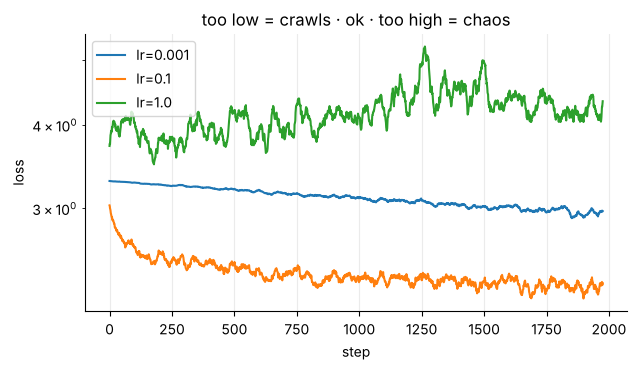

In [36]:
res = {}
for lr in [0.001, 0.1, 1.0]:
    n = train_net(make_net(use_bn=False, gain=5/3), steps=2000, lr=lr)
    res[lr] = n
    ratio = np.mean([u[1] for u in n['ud'][-500:]])
    print(f'lr={lr:<6}  final loss {np.mean(n["lossi"][-200:]):.3f}   update:data (log10) of first W ≈ {ratio:+.2f}')
plt.figure(figsize=(7, 3.6))
for lr, n in res.items(): plt.plot(smooth(n['lossi'], 25), label=f'lr={lr}')
plt.yscale('log'); plt.xlabel('step'); plt.ylabel('loss'); plt.legend(); plt.title('too low = crawls · ok · too high = chaos'); plt.show()

**Reading it.** lr = 0.001 sits at ≈ −4.9 (≈ 10⁻⁵ of the weights per step) → crawls (loss ≈ 2.96). lr = 0.1, the lecture's choice, sits at ≈ −2.5 → trains well; that's "close enough to −3" for the rule of thumb. lr = 1 sits at ≈ −1.6 → unstable (loss ≈ 4.2). The ratio told us all of this from the first few hundred steps.

### 🔬 Experiment D — the last layer: why `γ *= 0.1` / `W *= 0.1` (back to §1, now in a deep net)

In [37]:
def loss_at_init(last_scale, use_bn):
    net = make_net(use_bn=use_bn, gain=5/3)
    with torch.no_grad():
        if use_bn: net['layers'][-1].gamma.fill_(last_scale)
        else:
            net['layers'][-1].weight *= last_scale / 0.1
    g = net['g']; ix = torch.randint(0, Xtr.shape[0], (4096,), generator=g)
    x = net['C'][Xtr[ix]].view(4096, -1)
    for l in net['layers']: x = l(x)
    return F.cross_entropy(x, Ytr[ix]).item()
for sc in [0.1, 1.0, 3.0]:
    print(f'last-layer scale {sc:>4}:  step-0 loss  no-BN {loss_at_init(sc, False):6.2f}   BN {loss_at_init(sc, True):6.2f}    (ideal {-math.log(1/27):.2f})')

last-layer scale  0.1:  step-0 loss  no-BN   3.30   BN   3.30    (ideal 3.30)
last-layer scale  1.0:  step-0 loss  no-BN   3.52   BN   3.73    (ideal 3.30)
last-layer scale  3.0:  step-0 loss  no-BN   5.03   BN   6.40    (ideal 3.30)


**Reading it.** Scale 0.1 gives the ideal 3.30; scale 1 → ≈ 3.5–3.7; scale 3 → 5–6.4. BatchNorm does **not** protect the output layer: it normalises the logits to unit std and then `γ` sets their loudness — with γ = 1 the logits have std 1, which is exactly the "std 1 → loss ≈ 3.75" row from §1. That's why the lecture still scales the last layer down.

---
## 8 · Self-test, exercises, cheat-sheet

### ❓ Self-test (click to reveal)

<details><summary><b>Q1.</b> At step 0 your 27-class loss is 27. What's wrong, and what should it be?</summary>
The last layer produces large, confident logits. Expected loss ≈ −ln(1/27) ≈ 3.30. Fix: scale the last-layer weights by ~0.01–0.1 and set the output bias to 0.
</details>

<details><summary><b>Q2.</b> Why does a saturated tanh stop a neuron learning?</summary>
Backprop multiplies the incoming gradient by (1 − tanh²). At ±1 that factor is ≈ 0, so nothing flows to the weights below. If it's saturated for <i>all</i> examples it can never recover (dead neuron).
</details>

<details><summary><b>Q3.</b> A Linear layer has fan_in = 400, inputs and weights are unit-variance. What's the output std, and what weight std fixes it?</summary>
Output std ≈ √400 = 20 (a sum of 400 independent terms). Use weight std = 1/√400 = 0.05 (times the gain of the following non-linearity, e.g. 5/3 for tanh).
</details>

<details><summary><b>Q4.</b> Why is the tanh gain 5/3 and not 1?</summary>
tanh squashes: unit-Gaussian in → std ≈ 0.63 out. The extra gain compensates the shrinkage so the signal doesn't fade layer by layer. (ReLU zeroes half the signal → gain √2.)
</details>

<details><summary><b>Q5.</b> What does BatchNorm compute, and what are γ and β for?</summary>
For each neuron: subtract the batch mean, divide by the batch std (→ mean 0, std 1). γ and β are learnable scale and shift so the net can undo/adjust the normalisation if that's better.
</details>

<details><summary><b>Q6.</b> Why is the bias before a BatchNorm layer pointless?</summary>
BN subtracts the per-neuron mean, which cancels any constant added by the bias. β in BN plays that role.
</details>

<details><summary><b>Q7.</b> What's the main downside of BatchNorm?</summary>
It couples the examples in a batch: an example's output depends on its batch-mates. Causes subtle bugs, train/eval mismatch, breaks at batch size 1, awkward for sequence models. LayerNorm/GroupNorm avoid it.
</details>

<details><summary><b>Q8.</b> How do you get BN statistics at inference time?</summary>
Use running (EMA) mean/var collected during training, or compute exact mean/var over the training set in a post-training "calibration" pass. Remember <code>.eval()</code>/<code>training=False</code>.
</details>

<details><summary><b>Q9.</b> You see an update:data ratio around −5 for all layers. What does it mean and what do you try?</summary>
Parameters move ~0.001 % of their size per step — learning is far too slow. Increase the learning rate by ~10–100× (or check for vanishing gradients if some layers sit far below the others).
</details>

<details><summary><b>Q10.</b> With BatchNorm, does initial weight scale still matter?</summary>
Forward activations: no (scale-invariant). Effective learning rate: yes — larger weights ⇒ smaller relative updates for the same lr, which shows up in the update:data ratio.
</details>

### 🛠 Exercises (from the lecture, plus a few more)
1. **Zero init.** Set *all* weights and biases to 0. What is the loss at step 0? Which parameters get non-zero gradients? Does the net ever learn? *(Hint: the symmetry argument in §1.)*
2. **ReLU.** Replace `Tanh` with a `ReLU` brick and use gain `√2`. Re-run Experiment A and compare activation/saturation (here: "% dead") panels.
3. **LayerNorm.** Write a `LayerNorm1d` brick (normalise over dim 1 instead of dim 0, no running stats). Does its output for example 0 change when the batch changes? (Re-run the §4 coupling test.)
4. **Learning-rate finder.** Use the update:data ratio to pick `lr` for the BN net automatically: increase `lr` until the mean ratio crosses −3.
5. **Calibrate vs EMA.** In §5 try `momentum = 0.1` instead of 0.001 for the running stats. How big is the gap between running and calibrated val loss? Why?
6. **Beat 2.10.** Use what you learned (depth, width, embedding size, lr schedule) to push the validation loss lower. The lecture's challenge to viewers.

### 📌 Cheat-sheet

| Symptom | Diagnosis | Fix |
|---|---|---|
| Step-0 loss ≫ ln(vocab) | last layer too confident | `W_last *= 0.01~0.1`, `b_last = 0` |
| Many activations at ±1, tiny gradients | tanh saturation | smaller gain / `W / √fan_in`, or BatchNorm |
| Activation std shrinks with depth | gain too low | raise gain (tanh 5/3, ReLU √2) |
| Activation std grows with depth | gain too high | lower gain |
| Update:data ≪ −3 | lr too low | raise lr |
| Update:data ≫ −3 or loss spikes | lr too high | lower lr |
| Test numbers differ from train in weird ways | BN in train mode / stale running stats | `training=False`, calibrate stats |
| Results depend on batch composition | BN coupling | LayerNorm/GroupNorm, larger batch |

**Formulas to memorise**

* Initial loss: $-\ln(1/V)$
* Kaiming: $\;w\sim\mathcal N\big(0,\ (\text{gain}/\sqrt{\text{fan\_in}})^2\big)$, gains: linear 1 · tanh 5/3 · ReLU √2
* BN: $y=\gamma\,\dfrac{x-\mu_B}{\sqrt{\sigma_B^2+\varepsilon}}+\beta$ ; running $\leftarrow(1-m)\,\text{running}+m\,\text{batch}$
* Healthy training: $\log_{10}\big(\text{std}(\text{lr}\cdot g)/\text{std}(w)\big)\approx -3$

### 🎬 Further watching
* Karpathy — [full lecture](https://www.youtube.com/watch?v=P6sfmUTpUmc) (time-stamps in the table at the top) · previous lectures: micrograd, makemore parts 1–2
* 3Blue1Brown — Neural networks series: [Ch.1](https://www.youtube.com/watch?v=aircAruvnKk) · [Ch.2 gradient descent](https://www.youtube.com/watch?v=IHZwWFHWa-w) · [Ch.3 backprop](https://www.youtube.com/watch?v=Ilg3gGewQ5U) · [Ch.4 calculus](https://www.youtube.com/watch?v=tIeHLnjs5U8) · [Central Limit Theorem](https://www.youtube.com/watch?v=zeJD6dqJ5lo)
* Papers: He et al. 2015 (*Delving Deep into Rectifiers* — Kaiming init) · Ioffe & Szegedy 2015 (*Batch Normalization*) · Ba et al. 2016 (*Layer Normalization*)

*Next in the series:* **makemore Part 4 — Becoming a Backprop Ninja** (manual backprop through this exact BN network).